In [1]:
!pip install -q lightgbm shap lifelines causalml streamlit joblib pyngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 37.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 14.7 MB/s eta 0:00:00


In [40]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from lifelines import CoxPHFitter, KaplanMeierFitter
from causalml.inference.tree import UpliftTreeClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import joblib


In [3]:
#https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset?resource=download
# 1. Download IBM Telco Churn Dataset
d1 = pd.read_excel('/content/Telco_customer_churn.xlsx')
d1

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


In [4]:
# 2. Convert and save to a CSV file
d1.to_csv("telcos_customerchurnpred.csv", index=False)

In [5]:
df=pd.read_csv('/content/telcos_customerchurnpred.csv')
df

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


In [6]:
# Load data into a local SQLite database (mimicking relational data storage)
conn = sqlite3.connect("customer_churn.db")
df.to_sql("telco_churn", conn, if_exists="replace", index=False)

# Query back from the database to verify ingestion
query = "SELECT * FROM telco_churn"
df = pd.read_sql(query, conn)
print("Data loaded successfully! Shape:", df.shape)

Data loaded successfully! Shape: (7043, 33)


In [7]:
df['Churn Label'].unique()

array(['Yes', 'No'], dtype=object)

In [8]:
df['Tenure Months'].unique()

array([ 2,  8, 28, 49, 10,  1, 47, 17,  5, 34, 11, 15, 18,  9,  7, 12, 25,
       68, 55, 37,  3, 27, 20,  4, 58, 53, 13,  6, 19, 59, 16, 52, 24, 32,
       38, 54, 43, 63, 21, 69, 22, 61, 60, 48, 40, 23, 39, 35, 56, 65, 33,
       30, 45, 46, 62, 70, 50, 44, 71, 26, 14, 41, 66, 64, 29, 42, 67, 51,
       31, 57, 36, 72,  0])

In [9]:
# Data Cleaning
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
df["Total Charges"].fillna(df["Total Charges"].median(), inplace=True)

# Encode Churn to binary target
df["Churn_Binary"] = df["Churn Label"].apply(lambda x: 1 if x == "Yes" else 0)

# Feature Engineering
df["TenureGroup"] = pd.cut(
    df["Tenure Months"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-1 yr", "1-2 yrs", "2-4 yrs", "4+ yrs"],
)
df["AvgMonthlySpendRate"] = df["Total Charges"] / (df["Tenure Months"] + 1)
df["HasStreaming"] = (
    (df["Streaming TV"] == "Yes") | (df["Streaming Movies"] == "Yes")
).astype(int)

print(df[["Tenure Months", "Total Charges", "AvgMonthlySpendRate", "Churn_Binary"]].head())

   Tenure Months  Total Charges  AvgMonthlySpendRate  Churn_Binary
0              2         108.15            36.050000             1
1              2         151.65            50.550000             1
2              8         820.50            91.166667             1
3             28        3046.05           105.036207             1
4             49        5036.30           100.726000             1


/tmp/ipykernel_4968/3923108371.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Total Charges"].fillna(df["Total Charges"].median(), inplace=True)


EDA ANALYSIS

In [10]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

/tmp/ipykernel_4968/3755419996.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Churn Label', data=df, palette='Set2')


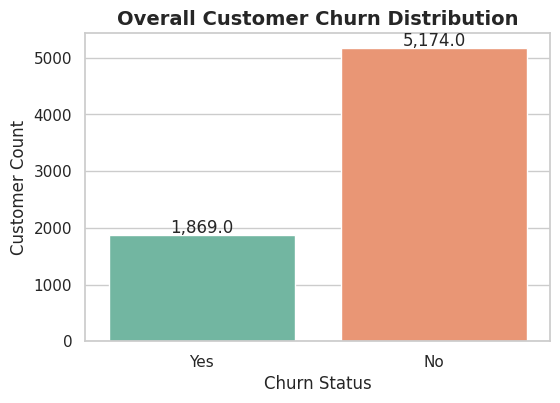

In [12]:
# 1. Churn Rate Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn Label', data=df, palette='Set2')
plt.title('Overall Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

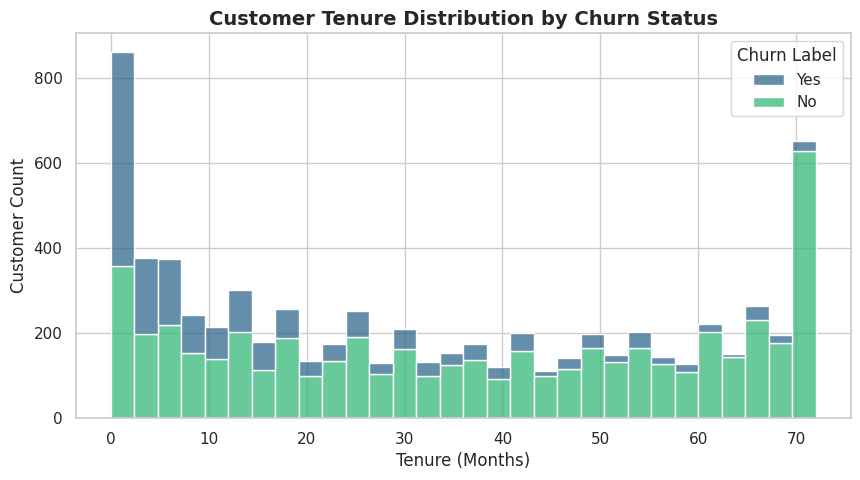

In [15]:
# 2. Tenure vs Churn Analysis (Usage Trends)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Tenure Months', hue='Churn Label', multiple='stack', palette='viridis', bins=30)
plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Months)', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.show()

/tmp/ipykernel_4968/2036953986.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y='Monthly Charges', data=df, palette='Set3')


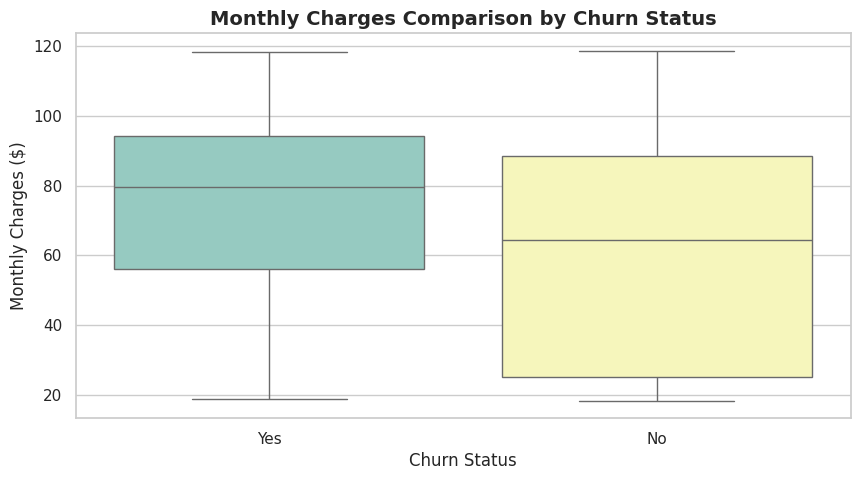

In [16]:
# 3. Monthly Charges vs Churn
plt.figure(figsize=(10, 5))
sns.boxplot(x='Churn Label', y='Monthly Charges', data=df, palette='Set3')
plt.title('Monthly Charges Comparison by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Monthly Charges ($)', fontsize=12)
plt.show()

<Figure size 800x500 with 0 Axes>

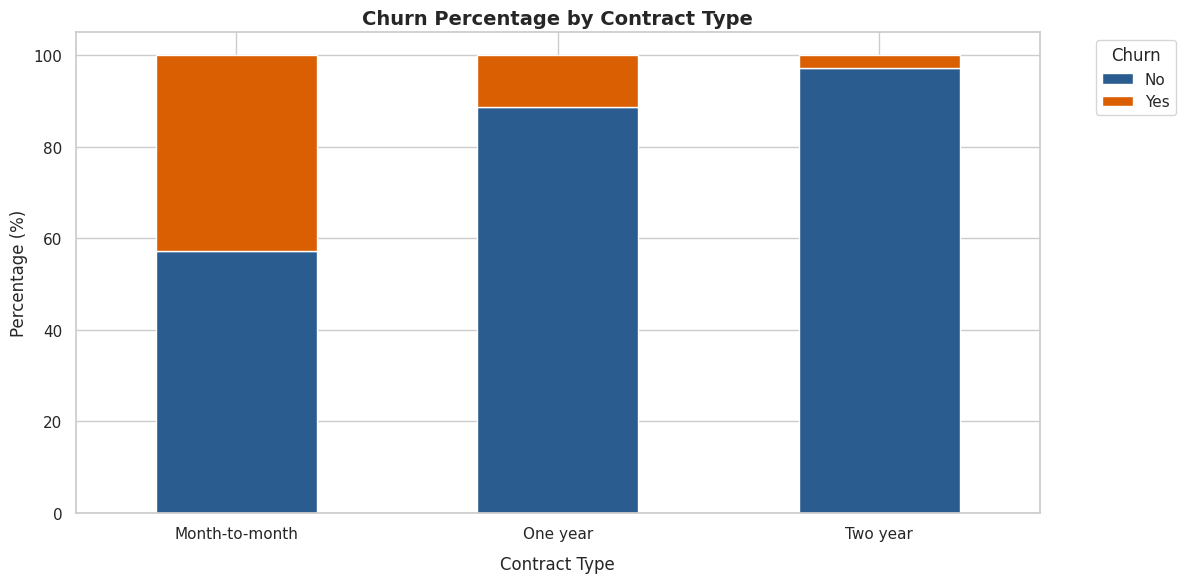

In [18]:
# 4. Contract Type vs Churn (Contract Type Impact)
plt.figure(figsize=(8, 5))
contract_churn = pd.crosstab(df['Contract'], df['Churn Label'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'])
plt.title('Churn Percentage by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type', fontsize=12, labelpad=10)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

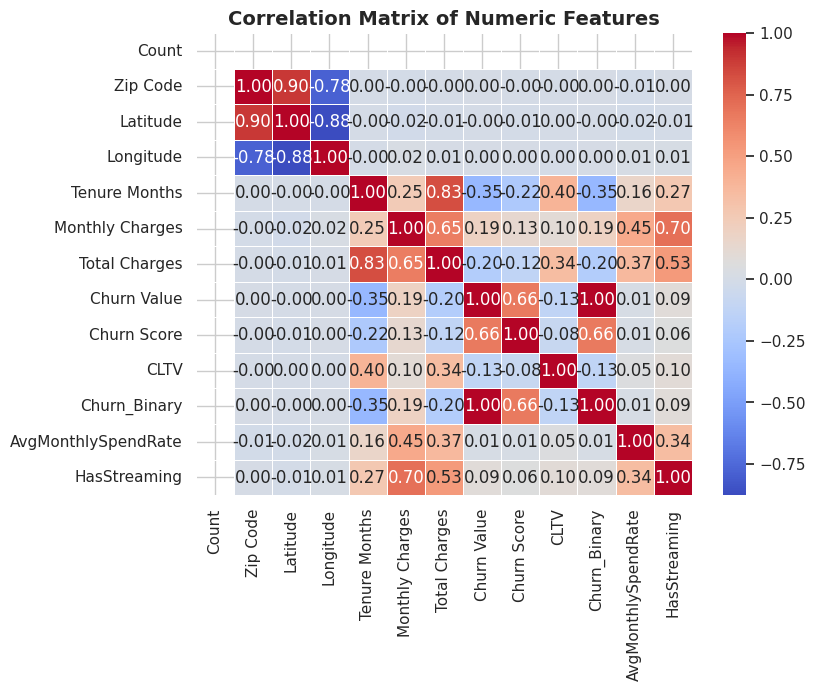

In [19]:
# 5. Correlation Heatmap of Numeric Features
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numeric Features', fontsize=14, fontweight='bold')
plt.show()

Churn Classifier with LightGBM & SHAP

In [26]:

# Prepare features
cat_cols = [
    "Gender",
    "Partner",
    "Dependents",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Tenure Months",
]

df_model = df.copy()
for col in cat_cols:
    df_model[col] = LabelEncoder().fit_transform(
        df_model[col].astype(str)
    )

features = [
    c
    for c in cat_cols
    + [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "AvgMonthlySpendRate",
        "HasStreaming",
    ]
    if c in df_model.columns
]
X = df_model[features]
y = df_model["Churn_Binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train LightGBM Classifier
clf = lgb.LGBMClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# SHAP Explainer
explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_test)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1469, number of negative: 4165
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007628 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 371
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.260738 -> initscore=-1.042134
[LightGBM] [Info] Start training from score -1.042134


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [24]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason', 'Churn_Binary', 'TenureGroup',
       'AvgMonthlySpendRate', 'HasStreaming'],
      dtype='object')

Survival Analysis using Lifelines

In [29]:
# Prepare survival dataframe
surv_df = df[["Tenure Months", "Churn_Binary", "Monthly Charges"]].copy()
surv_df.columns = ["duration", "event", "Monthly Charges"]

# Kaplan-Meier Estimator
kmf = KaplanMeierFitter()
kmf.fit(surv_df["duration"], event_observed=surv_df["event"])
print(f"Median customer survival duration: {kmf.median_survival_time_} months")

# Cox Proportional Hazards Model
cph = CoxPHFitter()
cph.fit(surv_df, duration_col="duration", event_col="event")
cph.print_summary()

Median customer survival duration: inf months


<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -15621.29
         time fit was run = 2026-10-22 13:21:15 UTC

---
                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                        
Monthly Charges  0.01      1.01      0.00            0.00            0.01                1.00                1.01

                 cmp to    z      p  -log2(p)
covariate                                    
Monthly Charges    0.00 7.83 <0.005     47.54
---
Concordance = 0.51
Partial AIC = 31244.59
log-likelihood ratio test = 63.49 on 1 df
-log2(p) of ll-ratio test = 49.14

Uplift Modeling using CausalML

In [36]:
# Simulate a random marketing campaign treatment (0 = Control, 1 = Treated with offer)
np.random.seed(42)
df_model["treatment"] = np.random.binomial(1, 0.5, size=len(df_model))
# Simulate uplift response (conversion/staying behavior)
df_model["conversion"] = (
    1 - df_model["Churn_Binary"]
) + 0.1 * df_model["treatment"]
df_model["conversion"] = df_model["conversion"].clip(0, 1).round()

# Setup features for causal tree
X_uplift = df_model[features].values
treatment_col = df_model["treatment"].values
y_uplift = df_model["conversion"].values

# Fit CausalML Uplift Tree
upt = UpliftTreeClassifier(max_depth=3, random_state=42,control_name=0)
upt.fit(X_uplift, treatment=treatment_col, y=y_uplift)

UpliftTreeClassifier(control_name=0, random_state=42)

Customer Lifetime Value (CLV) & Clustering

In [39]:
# Compute CLV (Simple approximation: MonthlyCharges * tenure)
df["CLV"] = df["Monthly Charges"] * df["Tenure Months"]

# Clustering features
cluster_data = df[["Tenure Months", "Monthly Charges", "CLV"]].copy()
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Segment"] = kmeans.fit_predict(scaled_data)

print(df.groupby("Segment")[["Tenure Months", "Monthly Charges", "CLV"]].mean())

         Tenure Months  Monthly Charges          CLV
Segment                                             
0            29.511379        26.563400   809.962076
1            13.308976        74.918472  1036.003023
2            58.601185        89.765451  5249.853669


In [41]:
joblib.dump(clf, "churn_lgb_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")
df.to_pickle("processed_churn_data.pkl")
print("All model artifacts saved successfully via joblib!")

All model artifacts saved successfully via joblib!
